# Results comparison across the experiment cells

This notebook trains nothing. It reads the executed `.ipynb` files of the
experiment cells and extracts the classification reports that are already stored
in their saved outputs. Runtime is a few seconds, independent of the size of the
data.

Every modeling notebook prints, for each model and each split, an in-domain
report and a report on the separate university capture. Both are parsed here.

The four cells of the design matrix are E1 to E4. E5 and E6 are the mixed ecosystem runs (Samsung A54, Buds FE and
AirTag against iPhone 12, AirPods and SmartTag), trained on a 6 h Seewis capture
instead of 10 h. The apartment run is kept as a
legacy row for comparison, because E4 was re-recorded in Seewis.


In [1]:
import json, re, pathlib
import pandas as pd
import matplotlib.pyplot as plt

BASE = pathlib.Path(".")
BASELINE = 1 / 3  # macro F1 of a model that predicts background only

EXPERIMENTS = [
    ("E1 apple same", "modeling_10h2h_IP12_AAP1P_ST_SameDist.ipynb", True),
    ("E2 apple diff", "modeling_10h2h_IP12_AAP1P_ST_DiffDist.ipynb", True),
    ("E3 samsung same", "modeling_10h2h_sa54_sbfe_aat_sameDist.ipynb", True),
    ("E4 samsung diff", "modeling_10h2h_sa54_sbfe_aat_diffDist.ipynb", True),
    ("E5 mixed same", "modeling_6h2h_A54FEAirtags_IP12PodsST_SameDist.ipynb", True),
    ("E6 mixed diff", "modeling_6h2h_A54FEAirtags_IP12PodsST_DiffDist.ipynb", True),
    ("legacy samsung diff apartment", "../../archive/modeling/modeling_10h2h_sa54_sbfe_aat_diffDist_apartment.ipynb", False),
]

In [2]:
def notebook_text(path):
    """All stdout and text output of the code cells of an executed notebook."""
    d = json.loads(path.read_text(encoding="utf-8"))
    parts = []
    for c in d["cells"]:
        if c["cell_type"] != "code":
            continue
        for o in c.get("outputs", []):
            if o.get("output_type") == "stream":
                parts.append("".join(o.get("text", [])))
            elif o.get("output_type") in ("execute_result", "display_data"):
                t = o.get("data", {}).get("text/plain")
                if t:
                    parts.append("".join(t))
    return "\n".join(parts)


def parse_reports(block):
    """Per class F1 and macro F1 from the two classification reports in a block."""
    reports, cur = [], {}
    for line in block.splitlines():
        m = re.match(r"\s*([012])\s+([0-9.]+)\s+([0-9.]+)\s+([0-9.]+)\s+(\d+)\s*$", line)
        if m:
            cur[int(m.group(1))] = (float(m.group(2)), float(m.group(3)), float(m.group(4)))
            continue
        m = re.match(r"\s*accuracy\s+([0-9.]+)\s+(\d+)\s*$", line)
        if m:
            cur["accuracy"] = float(m.group(1))
            continue
        m = re.match(r"\s*macro avg\s+([0-9.]+)\s+([0-9.]+)\s+([0-9.]+)\s+(\d+)\s*$", line)
        if m:
            cur["macro_f1"] = float(m.group(3))
            cur["n"] = int(m.group(4))
            reports.append(cur)
            cur = {}
    return reports


def extract_results(base, experiments):
    rows = []
    for label, fname, is_cell in experiments:
        p = base / fname
        if not p.exists():
            print("missing notebook:", fname)
            continue
        txt = notebook_text(p)
        pattern = (r"STARTING MODEL:\s*(.*?)\s+WITH GROUPED SPLIT MODE:\s*(\w+)"
                   r"\s+AND TEST SIZE:\s*([0-9.]+)\s+LABEL:\s*(\w+)")
        for m in re.finditer(pattern, txt):
            start = m.end()
            nxt = re.search(r"STARTING MODEL:", txt[start:])
            block = txt[start:start + nxt.start()] if nxt else txt[start:]
            reports = parse_reports(block)
            if len(reports) < 2:
                continue
            ind, tr = reports[0], reports[1]
            rows.append(dict(
                experiment=label,
                is_cell=is_cell,
                model=m.group(1).strip(),
                split="grouped" if m.group(2) == "True" else "packet",
                label=m.group(4),
                in_acc=ind.get("accuracy"),
                in_macro_f1=ind.get("macro_f1"),
                in_f1_bg=ind.get(0, (None, None, None))[2],
                in_f1_g1=ind.get(1, (None, None, None))[2],
                in_f1_g2=ind.get(2, (None, None, None))[2],
                tr_acc=tr.get("accuracy"),
                tr_macro_f1=tr.get("macro_f1"),
                tr_f1_bg=tr.get(0, (None, None, None))[2],
                tr_f1_g1=tr.get(1, (None, None, None))[2],
                tr_f1_g2=tr.get(2, (None, None, None))[2],
                tr_n=tr.get("n"),
            ))
    return pd.DataFrame(rows)

In [3]:
df_all = extract_results(BASE, EXPERIMENTS)
print(f"{len(df_all)} runs extracted from {df_all['experiment'].nunique()} notebooks")
# The rerun notebooks contain both labels. The tables below are the three class task;
# the binary rows (label group_label) are kept in df_all and in the exported csv.
# For the binary task, MCC, AUC-PR, majority vote and significance tests see
# code/analysis/01_metrics_and_significance.ipynb.
print(df_all.groupby(['experiment', 'label'])['model'].nunique().to_string())
df = df_all[df_all['label'] == 'group_label_multi'].copy()
df.head()

78 runs extracted from 7 notebooks
experiment                     label            
E1 apple same                  group_label          3
                               group_label_multi    3
E2 apple diff                  group_label          3
                               group_label_multi    3
E3 samsung same                group_label          3
                               group_label_multi    3
E4 samsung diff                group_label          3
                               group_label_multi    3
E5 mixed same                  group_label          3
                               group_label_multi    3
E6 mixed diff                  group_label          3
                               group_label_multi    3
legacy samsung diff apartment  group_label_multi    3


,experiment,is_cell,model,split,label,in_acc,in_macro_f1,in_f1_bg,in_f1_g1,in_f1_g2,tr_acc,tr_macro_f1,tr_f1_bg,tr_f1_g1,tr_f1_g2,tr_n
0,E1 apple same,True,Random Forest,packet,group_label_multi,0.96,0.94,1.00,0.91,0.91,1.00,0.90,1.00,0.85,0.85,15405
1,E1 apple same,True,Random Forest,grouped,group_label_multi,0.94,0.91,1.00,0.87,0.85,1.00,0.83,1.00,0.76,0.74,11953
2,E1 apple same,True,Multi-layer Perceptron,packet,group_label_multi,0.86,0.79,1.00,0.71,0.67,0.99,0.77,1.00,0.73,0.58,15405
3,E1 apple same,True,Multi-layer Perceptron,grouped,group_label_multi,0.87,0.78,0.99,0.65,0.71,1.00,0.77,1.00,0.58,0.72,11953
4,E1 apple same,True,Stochastic Gradient Descent,packet,group_label_multi,0.73,0.62,0.90,0.46,0.50,0.95,0.50,0.98,0.23,0.30,15405


## Random forest, macro F1

The grouped split is the honest in-domain estimate. The transfer column is the
separate two hour university capture. A model that predicts only background
reaches macro F1 0.33, so read the transfer column against that line.

In [4]:
rf = df[df["model"] == "Random Forest"].copy()
cols = ["experiment", "split", "in_acc", "in_macro_f1", "tr_acc", "tr_macro_f1",
        "tr_f1_g1", "tr_f1_g2", "tr_n"]
rf[cols].sort_values(["experiment", "split"]).reset_index(drop=True)

,experiment,split,in_acc,in_macro_f1,tr_acc,tr_macro_f1,tr_f1_g1,tr_f1_g2,tr_n
0,E1 apple same,grouped,0.94,0.91,1.00,0.83,0.76,0.74,11953
1,E1 apple same,packet,0.96,0.94,1.00,0.90,0.85,0.85,15405
2,E2 apple diff,grouped,0.90,0.89,1.00,0.87,0.79,0.80,12461
3,E2 apple diff,packet,0.95,0.94,1.00,0.90,0.84,0.86,14492
4,E3 samsung same,grouped,0.97,0.97,0.99,0.94,0.85,0.96,5434
5,E3 samsung same,packet,0.99,0.99,0.99,0.95,0.87,0.99,7458
6,E4 samsung diff,grouped,1.00,1.00,1.00,0.98,0.93,1.00,6237
7,E4 samsung diff,packet,0.99,0.99,0.99,0.97,0.94,0.98,8310
8,E5 mixed same,grouped,0.89,0.90,0.99,0.88,0.98,0.66,4860
9,E5 mixed same,packet,0.95,0.95,0.99,0.94,0.99,0.82,6199


In [5]:
pivot = rf.pivot_table(index="experiment", columns="split",
                      values=["in_macro_f1", "tr_macro_f1"])
pivot = pivot.reindex([e[0] for e in EXPERIMENTS if e[0] in pivot.index])
pivot

in_macro_f1        tr_macro_f1       
split                             grouped packet     grouped packet
experiment                                                         
E1 apple same                        0.91   0.94        0.83   0.90
E2 apple diff                        0.89   0.94        0.87   0.90
E3 samsung same                      0.97   0.99        0.94   0.95
E4 samsung diff                      1.00   0.99        0.98   0.97
E5 mixed same                        0.90   0.95        0.88   0.94
E6 mixed diff                        0.91   0.93        0.91   0.93
legacy samsung diff apartment        0.83   0.94        0.37   0.46

## Per class F1 on the separate capture

A high macro average can hide one collapsed group, so both target classes are
shown separately. Background is omitted here.

In [6]:
order = [e[0] for e in EXPERIMENTS if e[0] in rf["experiment"].values]
per_class = (rf[rf["split"] == "grouped"]
             .set_index("experiment")[["tr_f1_bg", "tr_f1_g1", "tr_f1_g2"]]
             .reindex(order))
per_class

,tr_f1_bg,tr_f1_g1,tr_f1_g2
experiment,,,
E1 apple same,1.00,0.76,0.74
E2 apple diff,1.00,0.79,0.80
E3 samsung same,1.00,0.85,0.96
E4 samsung diff,1.00,0.93,1.00
E5 mixed same,1.00,0.98,0.66
E6 mixed diff,1.00,0.98,0.75
legacy samsung diff apartment,0.95,0.02,0.14


## In domain against transfer, grouped split

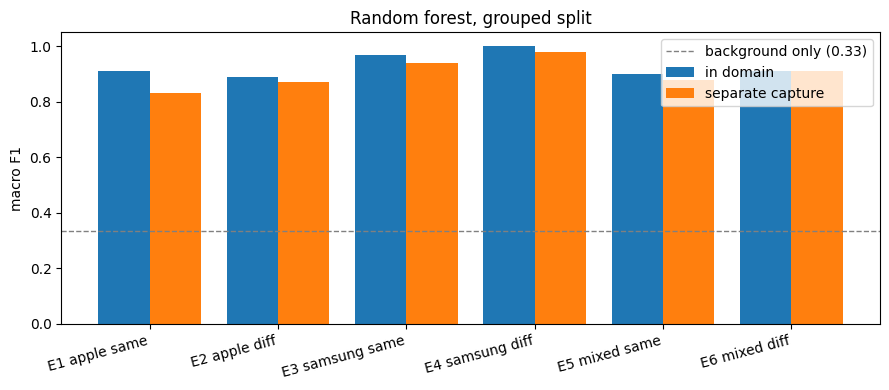

In [7]:
%matplotlib inline
cells_only = rf[(rf["split"] == "grouped") & rf["is_cell"]]
fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(cells_only))
ax.bar([i - 0.2 for i in x], cells_only["in_macro_f1"], width=0.4, label="in domain")
ax.bar([i + 0.2 for i in x], cells_only["tr_macro_f1"], width=0.4, label="separate capture")
ax.axhline(BASELINE, ls="--", lw=1, color="grey", label="background only (0.33)")
ax.set_xticks(list(x))
ax.set_xticklabels(cells_only["experiment"], rotation=15, ha="right")
ax.set_ylabel("macro F1")
ax.set_ylim(0, 1.05)
ax.set_title("Random forest, grouped split")
ax.legend()
plt.tight_layout()
plt.show()

## G1 and G2 on the separate capture

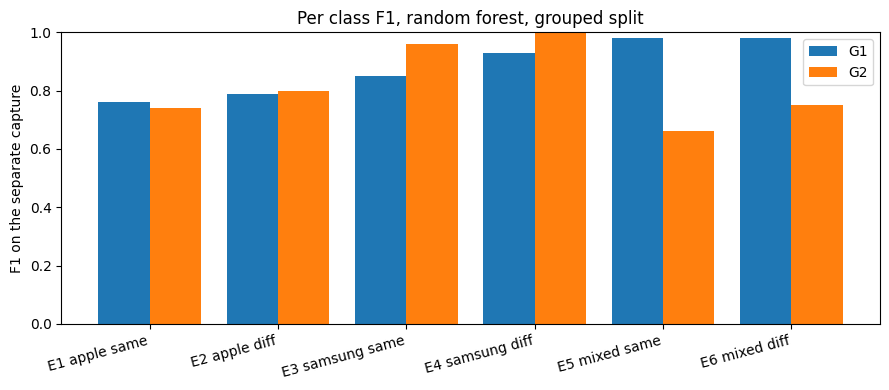

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([i - 0.2 for i in x], cells_only["tr_f1_g1"], width=0.4, label="G1")
ax.bar([i + 0.2 for i in x], cells_only["tr_f1_g2"], width=0.4, label="G2")
ax.set_xticks(list(x))
ax.set_xticklabels(cells_only["experiment"], rotation=15, ha="right")
ax.set_ylabel("F1 on the separate capture")
ax.set_ylim(0, 1.0)
ax.set_title("Per class F1, random forest, grouped split")
ax.legend()
plt.tight_layout()
plt.show()

## All models, transfer macro F1

Same table for the other two learners, to show that the collapse is not specific
to the forest.

In [9]:
all_models = df.pivot_table(index=["experiment", "split"], columns="model",
                            values="tr_macro_f1")
all_models = all_models.reindex([(e[0], s) for e in EXPERIMENTS if e[0] in df["experiment"].values
                                 for s in ("packet", "grouped")])
all_models

model                                  Multi-layer Perceptron  Random Forest  \
experiment                    split                                            
E1 apple same                 packet                     0.77           0.90   
                              grouped                    0.77           0.83   
E2 apple diff                 packet                     0.85           0.90   
                              grouped                    0.80           0.87   
E3 samsung same               packet                     0.99           0.95   
                              grouped                    0.97           0.94   
E4 samsung diff               packet                     1.00           0.97   
                              grouped                    1.00           0.98   
E5 mixed same                 packet                     0.91           0.94   
                              grouped                    0.87           0.88   
E6 mixed diff                 packet                     0.91           0.93   
                              grouped                    0.88           0.91   
legacy samsung diff apartment packet                     0.35           0.46   
                              grouped                    0.25           0.37   

model                                  Stochastic Gradient Descent  
experiment                    split                                 
E1 apple same                 packet                          0.50  
                              grouped                         0.44  
E2 apple diff                 packet                          0.63  
                              grouped                         0.54  
E3 samsung same               packet                          0.51  
                              grouped                         0.47  
E4 samsung diff               packet                          0.45  
                              grouped                         0.31  
E5 mixed same                 packet                          0.45  
                              grouped                         0.37  
E6 mixed diff                 packet                          0.57  
                              grouped                         0.51  
legacy samsung diff apartment packet                          0.38  
                              grouped                         0.35

## Export

The extracted table is written next to this notebook, so the numbers can be used
in the thesis without parsing notebooks again.

In [10]:
out = BASE / "results_summary.csv"
df_all.to_csv(out, index=False)
print("wrote", out.resolve())

wrote C:\Users\thoma\PycharmProjects\MasterThesisTLS\code\thesis\modeling\results_summary.csv
